# Улаанбаатарын агаарын бохирдол: PM2.5-ын шинжилгээ

**Гол асуулт:** Улаанбаатарын агаар хэр бохир вэ, 2019 оны түүхий нүүрсний хоригийн дараа сайжирсан уу?

| # | Асуулт |
|---|---|
| 1 | **Улирал:** Өвлийн агаар зунаас хэр их бохир вэ? |
| 2 | **Нүүрсний хориг:** 2019 оны 5-р сарын хоригийн дараа өвөл цэвэр болсон уу? |
| 3 | **Дүүргүүд:** Хотын аль хэсэг хамгийн бохир агаартай байсан бэ? |
| 4 | **Эрүүл мэнд:** Жилд хэдэн өдөр агаар эрүүл бус байдаг вэ? |

- **Өгөгдөл:** [OpenAQ API v3](https://openaq.org), Улаанбаатарын 10 мэдрэгчийн өдрийн дундаж PM2.5
- **Сан:** [`aiaa-eda-team4`](https://pypi.org/project/aiaa-eda-team4/) (4-р баг). Энэ notebook-д `def` бичээгүй, бүх функц сангаас ирнэ.
- **Нэгж:** µg/m³ (нэг шоо метр агаар дахь тоосонцрын микрограмм). ДЭМБ-ын өдрийн зөвлөмж 15, Монголын стандарт 50.

## 1. Сан суулгах

In [ ]:
%pip install -q aiaa-eda-team4

In [2]:
import os
import pandas as pd
import aiaa_eda_team4 as et

os.makedirs("data", exist_ok=True)      # цэвэрлэсэн CSV
os.makedirs("figures", exist_ok=True)   # графикууд
print("Сангийн хувилбар:", et.__version__)

Сангийн хувилбар: 0.1.0


## 2. Өгөгдөл

Өгөгдлийг `src/download_daily.py` скриптээр OpenAQ-аас татаж `data/ub_pm25_daily.csv`-д хадгалсан. Энд GitHub-аас шууд уншина, тиймээс Colab дээр ч ажиллана.

| Багана | Утга |
|---|---|
| `date` | Огноо (Улаанбаатарын цагаар) |
| `pm25` | Өдрийн дундаж PM2.5, µg/m³ |
| `coverage` | Тухайн өдөр бүртгэгдсэн цагийн хэмжилтийн % |
| `station` | Станцын нэр |
| `group` | A = АНУ-ын ЭСЯ, B = засгийн газрын 7 станц, C = Бөмбөгөр |
| `sensor_id` | OpenAQ-ийн мэдрэгчийн дугаар |

In [3]:
URL = "https://raw.githubusercontent.com/Orgil5683/Air_Pollution/main/data/ub_pm25_daily.csv"
df = pd.read_csv(URL, parse_dates=["date"])

print("Мөр:", len(df), "| Багана:", df.shape[1])
df.head()

Мөр: 10174 | Багана: 6


,date,pm25,coverage,station,group,sensor_id
0,2016-01-30,298.0,67.0,US Embassy,A,4686
1,2016-01-31,417.0,100.0,US Embassy,A,4686
2,2016-02-01,516.0,100.0,US Embassy,A,4686
3,2016-02-02,424.0,100.0,US Embassy,A,4686
4,2016-02-03,314.0,100.0,US Embassy,A,4686


In [4]:
df.groupby("station")["date"].agg(["min", "max", "count"])

,min,max,count
station,,,
Amgalan,2016-02-03,2019-03-14,968
Baruun 4 zam,2016-01-30,2019-03-14,981
Bayankhoshuu,2016-05-25,2019-03-14,842
Bukhiin urguu,2016-01-30,2019-03-14,1001
Bumbugur,2025-11-04,2026-10-18,317
MNB,2016-01-30,2019-03-14,999
Nisekh,2016-02-16,2019-03-14,947
Tolgoit,2016-01-30,2019-03-14,942
US Embassy,2016-01-30,2025-03-04,3177


## 3. Цэвэрлэгээ

### 3.1 Дутуу утга

In [5]:
et.missing_report(df)

,missing_count,missing_pct
pm25,584,5.7
date,0,0.0
coverage,0,0.0
station,0,0.0
group,0,0.0
sensor_id,0,0.0


### 3.2 Зөвхөн бүрэн өдрүүд

Цагийн хэмжилтийн 75%-иас доошгүйтэй өдрийг л үлдээнэ. Жишээ нь мэдрэгч зөвхөн өдрийн 12-18 цагт ажилласан бол оройн утаатай цагууд алга болж, тэр өдрийн дундаж хэт цэвэр харагдана.

In [6]:
clean = et.filter_coverage(df)            # coverage >= 75
clean = clean.dropna(subset=["pm25"])     # хоосон pm25-ыг хасна
print(len(df), "→", len(clean), "мөр")

10174 → 7597 мөр


### 3.3 Сэжигтэй үе: АНУ-ын ЭСЯ, 2021 оны 3-10-р сар

Сар бүрийн **медиан** PM2.5-ыг жилүүдээр харьцуулна (медиан нь цөөн хэт өдөрт нөлөөлөгддөггүй).

In [7]:
check = et.add_time_columns(clean)
us_check = check[check["station"] == "US Embassy"]
us_check.pivot_table(index="month", columns="year", values="pm25", aggfunc="median").round(0)[[2018, 2019, 2020, 2021, 2024]]

year,2018,2019,2020,2021,2024
month,,,,,
1,131.0,220.0,192.0,135.0,150.0
2,79.0,118.0,97.0,81.0,90.0
3,24.0,52.0,36.0,50.0,29.0
4,16.0,26.0,24.0,42.0,17.0
5,20.0,16.0,13.0,46.0,10.0
6,20.0,17.0,15.0,35.0,10.0
7,11.0,10.0,11.0,45.0,18.0
8,7.0,12.0,10.0,47.0,9.0
9,19.0,18.0,17.0,43.0,11.0


2021 оны зуны сарууд бусад жилийн мөн үеэс **3-4 дахин өндөр**, харин 1, 2, 12-р сар хэвийн. Бодит бохирдол (тоосон шуурга, ойн түймрийн утаа) хэдхэн хоног үргэлжилдэг, 8 сар биш. Мөн NAMEM-ийн албан ёсны 2021 оны жилийн дундаж 44 µg/m³ буюу 2020 оныхоос (49) бага байсан. Иймээс энэ үеийг **мэдрэгчийн алдаа** гэж үзэн хасав.

In [8]:
clean = et.drop_period(clean, "2021-03-01", "2021-10-31", station="US Embassy")
clean = et.add_time_columns(clean)        # year, month, winter багана нэмнэ

clean.to_csv("data/ub_pm25_clean.csv", index=False)
print("Цэвэрлэсний дараа:", len(clean), "мөр → data/ub_pm25_clean.csv")

Цэвэрлэсний дараа: 7433 мөр → data/ub_pm25_clean.csv


### 3.4 Хэт утга (IQR)

PM2.5 маш тэгш бус тархалттай: өвөл зунаас олон дахин өндөр. Тиймээс нэг хязгаартай IQR нь өвлийн **жирийн** утаатай өдрүүдийг хэт утга гэж андуурна. Сар бүрт тусад нь хязгаар тооцвол илүү шударга.

In [9]:
all_out = et.iqr_outliers(clean, "pm25")
month_out = et.iqr_outliers(clean, "pm25", by="month")

print("Нэг хязгаартай:", len(all_out), "| үүнээс 11-2-р сард:", all_out["month"].isin([11, 12, 1, 2]).sum())
print("Сар бүрийн хязгаартай:", len(month_out))

Нэг хязгаартай: 518 | үүнээс 11-2-р сард: 515
Сар бүрийн хязгаартай: 342


Хэт утгуудыг **хасаагүй**: эдгээр нь алдаа биш, бодит утаатай өдрүүд. Харин IQR нь өгөгдлийн хэлбэрийг ойлгоход тусалсан.

### 3.5 Өгөгдлийн цоорхой (АНУ-ын ЭСЯ)

Нүд бүр = тухайн сард бүрэн хэмжилттэй өдрийн тоо. Улаан = их дутуу.

In [10]:
us = clean[clean["station"] == "US Embassy"]
gaps = us.groupby(["year", "month"]).size().unstack(fill_value=0)
gaps.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=31)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2016,1,27,29,28,29,28,29,29,28,29,28,29
2017,29,15,0,9,29,28,20,18,23,28,22,7
2018,19,16,11,21,16,27,16,26,23,17,23,28
2019,27,26,29,27,28,26,27,19,25,25,28,24
2020,29,22,26,22,25,26,28,15,10,20,17,16
2021,27,17,0,0,0,0,0,0,0,0,28,29
2022,29,26,27,28,27,28,29,3,3,7,0,0
2023,0,0,0,0,0,0,0,0,0,12,25,27
2024,31,27,25,25,23,30,25,24,30,31,30,30


2017 оны 12-р сар (7 өдөр), 2022 оны 8-р сараас 2023 оны 9-р сар хүртэл мэдрэгч бараг ажиллаагүй. 2025 оны 3-р сараас хойш АНУ-ын Төрийн департамент өгөгдөл нийтлэхээ зогсоосон.

## 4. Дүгнэлт 1: Улирал

In [11]:
et.basic_stats(us, "pm25")

,count,mean,median,min,max,std
pm25,2111.0,63.6,32.0,0.0,516.0,71.3


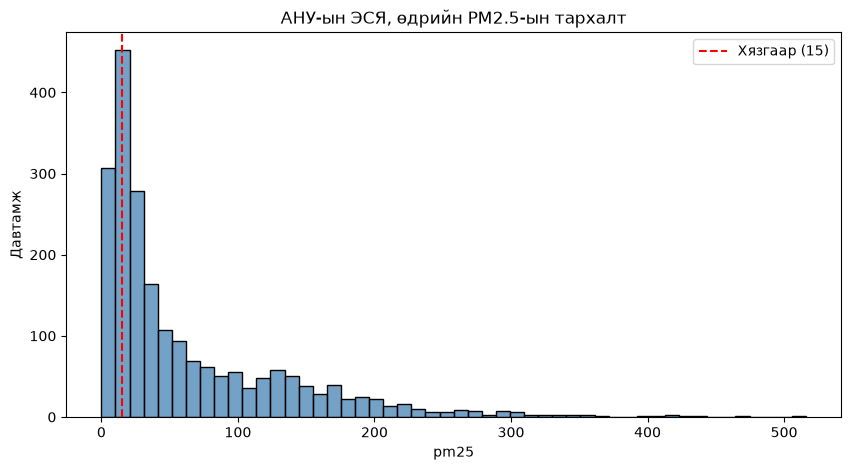

In [12]:
et.plot_hist(us, "pm25", path="figures/pm25_hist.png", vline=et.WHO_PM25_24H,
             title="АНУ-ын ЭСЯ, өдрийн PM2.5-ын тархалт");

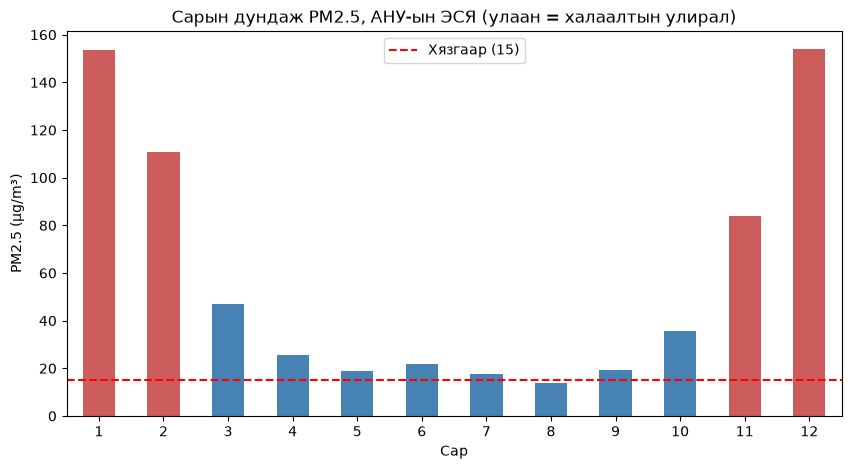

In [13]:
monthly = us.groupby("month")["pm25"].mean().round(1)
month_colors = ["indianred" if m in [11, 12, 1, 2] else "steelblue" for m in monthly.index]

et.plot_bar(monthly, path="figures/monthly_pm25.png", hline=et.WHO_PM25_24H, color=month_colors,
            title="Сарын дундаж PM2.5, АНУ-ын ЭСЯ (улаан = халаалтын улирал)",
            xlabel="Сар", ylabel="PM2.5 (µg/m³)");

In [14]:
dec_jan = us[us["month"].isin([12, 1])]["pm25"].mean()
may_sep = us[us["month"].isin([5, 6, 7, 8, 9])]["pm25"].mean()
print(f"12, 1-р сар: {dec_jan:.1f} | 5-9-р сар: {may_sep:.1f} | {dec_jan / may_sep:.1f} дахин")
print(f"12, 1-р сар ДЭМБ-ын зөвлөмжөөс {dec_jan / et.WHO_PM25_24H:.0f} дахин их")

12, 1-р сар: 153.8 | 5-9-р сар: 18.5 | 8.3 дахин
12, 1-р сар ДЭМБ-ын зөвлөмжөөс 10 дахин их


**Дүгнэлт 1:** 12, 1-р сар зунаас 8 орчим дахин бохир, ДЭМБ-ын зөвлөмжөөс 10 орчим дахин их. Шалтгаан нь халаалт: гэр хорооллын зууханд түлш түлэх, өвөл хүйтэн агаар газрын ойролцоо тогтож утааг дардаг (урвуу дулаан).

## 5. Дүгнэлт 2: Нүүрсний хориг (2019 оны 5-р сар)

In [15]:
winters = et.winter_summary(us)
winters["period"] = ["Хоригоос өмнө" if w <= 2019 else "Хоригийн дараа" for w in winters.index]
winters

,mean,count,period
winter,,,
2017,164.3,73,Хоригоос өмнө
2019,188.4,81,Хоригоос өмнө
2020,138.7,75,Хоригийн дараа
2021,117.0,60,Хоригийн дараа
2022,142.6,84,Хоригийн дараа
2024,120.5,85,Хоригийн дараа
2025,99.7,82,Хоригийн дараа


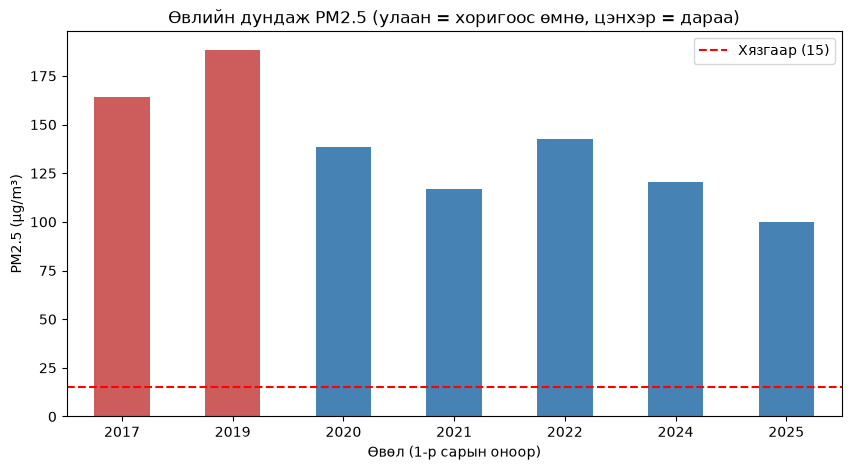

In [16]:
ban_colors = ["indianred" if w <= 2019 else "steelblue" for w in winters.index]

et.plot_bar(winters["mean"], path="figures/winter_coal_ban.png", hline=et.WHO_PM25_24H, color=ban_colors,
            title="Өвлийн дундаж PM2.5 (улаан = хоригоос өмнө, цэнхэр = дараа)",
            xlabel="Өвөл (1-р сарын оноор)", ylabel="PM2.5 (µg/m³)");

In [17]:
by_period = winters.groupby("period")["mean"].mean().round(1)
change = (by_period["Хоригийн дараа"] - by_period["Хоригоос өмнө"]) / by_period["Хоригоос өмнө"] * 100
print(by_period)
print(f"Өөрчлөлт: {change:.0f}%")

period
Хоригийн дараа    123.7
Хоригоос өмнө     176.4
Name: mean, dtype: float64
Өөрчлөлт: -30%


**Дүгнэлт 2:** Хоригийн дараах өвлүүд 30 орчим хувиар цэвэр, өвөл бүр хоригоос өмнөх хоёр өвлөөс доогуур. Энэ нь Ganbat нар (2020)-ын судалгаатай ижил чиглэлтэй.

**Анхааруулга:** Энэ нь **холбоо**, шалтгааныг батлахгүй. Хоригоос өмнө ердөө 2 бүрэн өвөл; цаг агаар (хүйтэн өвөл); 2020-21 оны COVID-ын хөл хорио; ганц станц.

## 6. Дүгнэлт 3: Дүүргүүд (2016-2019)

Шударга харьцуулахын тулд **8 станц бүгд** хэмжилт өгсөн өдрүүдийг л авна.

In [18]:
period = clean[(clean["date"] < "2019-03-15") & ((clean["group"] == "B") | (clean["station"] == "US Embassy"))]
wide = period.pivot_table(index="date", columns="station", values="pm25")
common = wide.dropna()
print("Бүх 8 станц хэмжилт өгсөн өдөр:", len(common))

Бүх 8 станц хэмжилт өгсөн өдөр: 221


In [19]:
compare = pd.DataFrame({
    "Өвөл (12-2-р сар)": common[common.index.month.isin(et.WINTER_MONTHS)].mean(),
    "Зун (6-8-р сар)": common[common.index.month.isin([6, 7, 8])].mean(),
}).round(1).sort_values("Өвөл (12-2-р сар)")
compare

,Өвөл (12-2-р сар),Зун (6-8-р сар)
station,,
Bukhiin urguu,107.2,20.0
Amgalan,126.3,18.7
US Embassy,144.9,23.1
Nisekh,148.2,19.1
Baruun 4 zam,163.2,16.6
MNB,224.3,17.7
Tolgoit,228.6,17.4
Bayankhoshuu,319.5,37.6


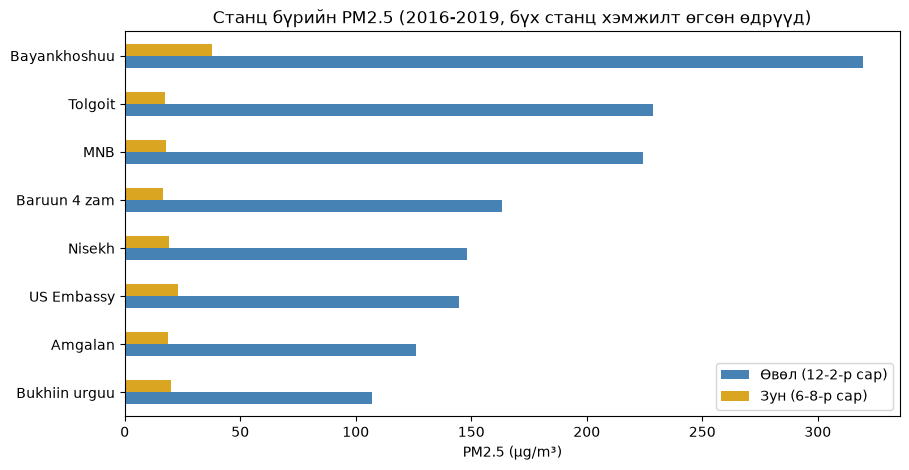

In [20]:
et.plot_bar(compare, path="figures/stations_winter_summer.png", horizontal=True,
            color=["steelblue", "goldenrod"],
            title="Станц бүрийн PM2.5 (2016-2019, бүх станц хэмжилт өгсөн өдрүүд)",
            xlabel="PM2.5 (µg/m³)");

**Дүгнэлт 3:** Өвөл Баянхошуу Бөхийн өргөөнөөс 3 орчим дахин бохир. Харин зун станцуудын ихэнх нь ойролцоо. Өвөл эрс зөрдөг нь хот даяарх замын хөдөлгөөнөөс илүү **орон нутгийн халаалтыг** заана. АНУ-ын ЭСЯ дундаж байр суурьтай тул хамгийн муу хэсгийн хүмүүс бүр их бохирдол амьсгалдаг.

## 7. Дүгнэлт 4: Эрүүл мэнд

Зөвхөн 1, 2, 11, 12-р сар бүр нь 15+ бүрэн өдөртэй жилүүдийг авна. Үгүй бол өвөл нь дутуу жил «цэвэр» харагдана. 2021 оныг (сэжигтэй зун хасагдсан) оруулахгүй.

In [21]:
winter_ok = (gaps[[1, 2, 11, 12]] >= 15).all(axis=1)
full_years = winter_ok[winter_ok].index.drop(2021, errors="ignore")
full = us[us["year"].isin(full_years)]

health = pd.DataFrame({
    "ДЭМБ-аас (15) дээш %": et.group_rate(full, by="year", col="pm25", threshold=et.WHO_PM25_24H),
    "MNS-аас (50) дээш %": et.group_rate(full, by="year", col="pm25", threshold=et.MNS_PM25_24H),
})
health

,ДЭМБ-аас (15) дээш %,MNS-аас (50) дээш %
year,,
2018,72.4,33.7
2019,76.2,38.3
2020,67.6,28.1
2024,61.3,29.3


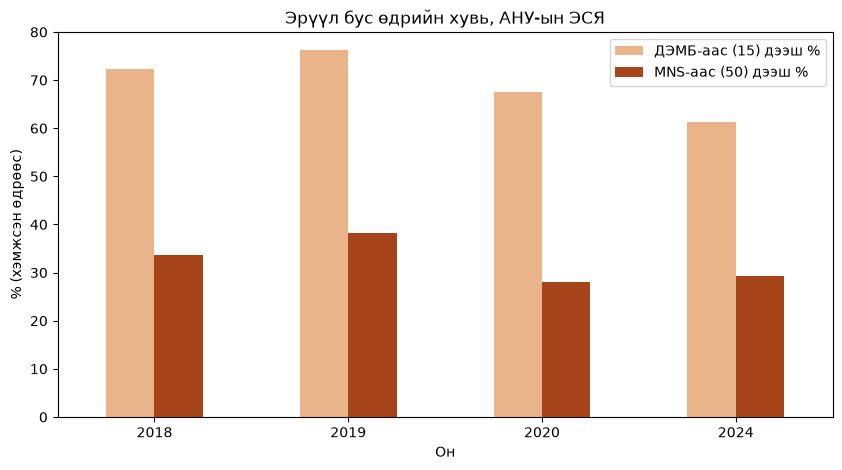

In [22]:
et.plot_bar(health, path="figures/unhealthy_days.png", color=["#E9B48A", "#A8441A"],
            title="Эрүүл бус өдрийн хувь, АНУ-ын ЭСЯ",
            xlabel="Он", ylabel="% (хэмжсэн өдрөөс)");

**Дүгнэлт 4:** Хамгийн цэвэр 2024 онд ч өдрийн **5-аас 3** нь ДЭМБ-ын зөвлөмжөөс дээш, **3 тутмын 1** орчим нь Монголын стандартыг зөрчсөн.

## 8. Дүгнэлт ба хязгаарлалт

**Дээрдсэн ч аюулгүй биш.**

| # | Дүгнэлт |
|---|---|
| 1 | 12, 1-р сар ДЭМБ-ын зөвлөмжөөс ~10 дахин, зунаас ~8 дахин бохир |
| 2 | Нүүрсний хоригийн дараа өвөл ~30% цэвэр (судалгаатай нийцэж байна) |
| 3 | Зарим хэсгийн өвлийн PM2.5 бусдаас 3 дахин их |
| 4 | Хамгийн сайн жилд ч өдрийн 5-аас 3 нь ДЭМБ-ын зөвлөмжөөс дээш |

**Хязгаарлалт**
- Хоригоос өмнө ердөө 2 бүрэн өвөл; 2017-18, 2022-23 оны өвөл мэдрэгч ажиллаагүй
- Цаг агаарын (температур) өгөгдөл ороогүй
- 2021 оны 3-10-р сарыг мэдрэгчийн алдаа гэж хассан
- АНУ-ын ЭСЯ-ны өгөгдөл 2025 оны 3-р сараас нийтлэгдээгүй
- Засгийн газрын станцууд OpenAQ дээр зөвхөн 2019 оны 3-р сар хүртэл

**Эх сурвалж:** OpenAQ API v3; ДЭМБ-ын агаарын чанарын удирдамж (2021); MNS 4585:2016; Ganbat et al. (2020), *Aerosol and Air Quality Research*; NAMEM (NEASPEC 2025).

## 9. Зургуудыг татах (Colab)

In [23]:
try:
    from google.colab import files
    !zip -qr figures.zip figures
    files.download("figures.zip")
except ImportError:
    print("Colab биш тул графикууд figures/ хавтсанд хадгалагдсан.")

Colab биш тул графикууд figures/ хавтсанд хадгалагдсан.
